# RTL Bug Dataset

**Source:** [shailja/Verilog_GitHub](https://huggingface.co/datasets/shailja/Verilog_GitHub), open-source Verilog files on Hugging Face.

**Method:** keep small single-module files (≤ 3,000 characters, which fit CodeT5+'s 512-token input), remove duplicates, then inject **one** realistic bug into most modules and leave the rest clean.

**One row = one Verilog module**: its code, whether it's buggy, the bug type, the line the bug is on, and the original (correct) code, which the repair model learns to produce.

## 1. Build the dataset

`make_dataset.py` streams the source, injects the bugs, and writes `data/rtl_bugs.csv`. It is skipped if the CSV already exists (delete the file to rebuild; takes a few minutes).

In [1]:
from pathlib import Path
import make_dataset

if not Path('data/rtl_bugs.csv').exists():
    make_dataset.main()

C:\School\RTL_Agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The six injected bug types:

| bug_type | What changes | Why it's a real bug |
|---|---|---|
| `blocking_in_seq` | `q <= d;` → `q = d;` | Blocking assignment in sequential logic causes race conditions |
| `missing_default` | deletes `default:` from a `case` | Synthesis infers an unintended latch |
| `width_off_by_one` | `[7:0]` → `[6:0]` | Bus loses its top bit |
| `inverted_condition` | `if (en)` → `if (!en)` | Logic fires in the wrong state |
| `reset_polarity` | `negedge rst` ↔ `posedge rst` | Design resets on the wrong edge |
| `wrong_operator` | `&`↔`|`, `+`↔`-` in an `assign` | Wrong arithmetic or logic result |

## 2. Load it

In [2]:
import pandas as pd

df = pd.read_csv('data/rtl_bugs.csv')
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')
df.dtypes

3,000 rows x 7 columns


module             str
code               str
label              str
bug_type           str
bug_line         int64
n_lines          int64
original_code      str
dtype: object

## 3. `df.head()`

The `code` column holds a whole Verilog file, so this preview skips the header comments, starts at the `module` keyword, and cuts the code short so the table fits. `original_code` is hidden here and shown in full in the next cell.

In [3]:
preview = df.drop(columns=['original_code']).copy()
preview['code'] = (preview['code']
                   .str.replace(r'(?s)^.*?(?=\bmodule\b)', '', regex=True)  # skip header comments
                   .str.replace(r'\s+', ' ', regex=True)                    # one line
                   .str[:45] + '...')
preview.head()

,module,code,label,bug_type,bug_line,n_lines
0,axi_protocol_converter_v2_1_b2s_simple_fifo,module axi_protocol_converter_v2_1_b2s_simple...,buggy,inverted_condition,48,84
1,testbed_hi_simulate,module testbed_hi_simulate; reg pck0; reg [6:...,buggy,width_off_by_one,30,117
2,Exp_Operation,module Exp_Operation #(parameter EW = 8) //Ex...,clean,none,-1,92
3,ddc,"module ddc(input clock, input reset, input en...",clean,none,-1,98
4,mux,"module mux(opA,opB,sum,dsp_sel,out); input [3...",buggy,blocking_in_seq,40,46


One full row, showing the bug as a diff against the original:

In [4]:
import difflib

row = df[df.bug_type == 'blocking_in_seq'].iloc[0]
print(f"module: {row.module}   bug: {row.bug_type}   line: {row.bug_line}\n")
for line in difflib.unified_diff(row.original_code.splitlines(), row.code.splitlines(),
                                 'original', 'buggy', lineterm='', n=2):
    print(line)

module: mux   bug: blocking_in_seq   line: 40

--- original
+++ buggy
@@ -38,5 +38,5 @@
 				out <= cout;
 			else if (dsp_sel == 2'b10)
-				out <= opB;
+				out = opB;
 			else if (dsp_sel == 2'b11)
 				out <= opA;


## 4. Plot: rows per bug type

Checks class balance. If one class dominated, a model could look accurate by always guessing it.

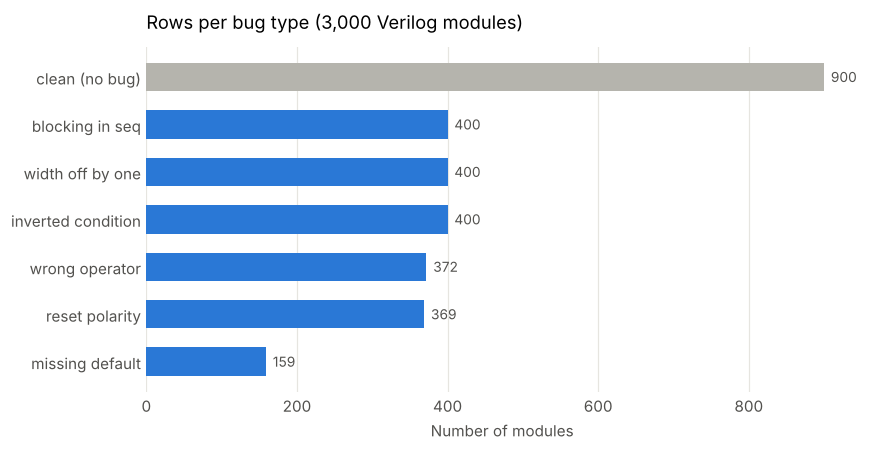

In [5]:
import matplotlib.pyplot as plt

counts = df['bug_type'].value_counts().sort_values()
labels = ['clean (no bug)' if k == 'none' else k.replace('_', ' ') for k in counts.index]
colors = ['#b5b4ad' if k == 'none' else '#2a78d6' for k in counts.index]

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)
bars = ax.barh(labels, counts.values, color=colors, height=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_width() + counts.max() * 0.01, b.get_y() + b.get_height() / 2,
            f'{v:,}', va='center', fontsize=9, color='#52514e')
ax.set_title(f'Rows per bug type ({len(df):,} Verilog modules)', loc='left', fontsize=12, pad=12)
ax.set_xlabel('Number of modules', color='#52514e')
ax.tick_params(colors='#52514e', length=0)
ax.xaxis.grid(True, color='#e6e5e0', linewidth=0.8)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.show()

## 5. Baseline

The simplest possible detector always predicts the most common class. Our CodeT5+ model must beat this.

In [6]:
majority = df['bug_type'].value_counts(normalize=True)
print(f"Most common class: '{majority.index[0]}'")
print(f"Baseline accuracy (always guess it): {majority.iloc[0]:.1%}")
print(f"Clean vs buggy: {(df.label == 'clean').mean():.0%} / {(df.label == 'buggy').mean():.0%}")

Most common class: 'none'
Baseline accuracy (always guess it): 30.0%
Clean vs buggy: 30% / 70%
